In [1]:
import numpy as np
import matplotlib.pyplot as plt# Later: load, align (if needed), and plot ΔP = P_B − P_A
from scipy.signal import find_peaks
from scipy.interpolate import interp1d
from scipy.signal import butter, filtfilt
from scipy.fft import fft, fftfreq
from scipy.integrate import simpson  # For numerical integration (Simpson's rule)
from scipy.integrate import quad

P_in = 6e5
P_out = 5.45e5
m_gas = 0.00015  # kg

zeta = 0.6
dP = P_in - P_out
dP_max = dP / (2 * zeta)  # Symmetric inlet/outlet
m_max = 0.001  # kg/s (adjust this to match amplitude; thesis implies ~0.001 for m_avg ~0.00037)



In [2]:
success = np.load("run_success.npz")
fail = np.load("run_fail.npz")
n_average=50000
t_success, P_success,v_success, m_success, b_gas_success, x_success = success["t"], success["P_cv"], success["v"], success["m"], success["b_gas"], success["x"]
t_fail, P_fail, v_fail, m_fail, b_gas_fail, x_fail = fail["t"], fail["P_cv"], fail["v"], fail["m"], fail["b_gas"], fail["x"]



In [3]:
### t=t, v=v, P_cv=P_cv, m=m,x=x,b_gas=b_gas
death = np.load("instant_death.npz")
t_death, P_death, v_death, m_death = death["t"], death["P_cv"], death["v"], death["m"]

In [4]:
fail_temp = np.load("fail_temp.npz")
T_fail = fail_temp["T_cv"]

success_temp = np.load("success_temp.npz")
T_success = success_temp["T_cv"]

In [5]:
def extract_envelopes(signal, peak_distance=None, smooth_cutoff_freq=None, sampling_freq=1.0):
    """
    Extracts the upper (max) and lower (min) envelopes of an oscillating signal.
    
    Parameters:
    - signal: np.ndarray, the input numerical array (pressure values).
    - peak_distance: int or None, minimum distance between peaks (in indices). If None, auto-detect based on dominant frequency.
                     For auto-detection, it's set to approximately half the dominant period to handle variations.
    - smooth_cutoff_freq: float or None, cutoff frequency for low-pass smoothing of envelopes.
                          If None, no smoothing is applied. Should be much lower than oscillation frequency.
    - sampling_freq: float, sampling frequency of the signal (for frequency detection and smoothing filter).
    
    Returns:
    - upper_envelope: np.ndarray, the upper envelope (max) as a function of index.
    - lower_envelope: np.ndarray, the lower envelope (min) as a function of index.
    """
    if not isinstance(signal, np.ndarray):
        signal = np.array(signal)
    
    indices = np.arange(len(signal))
    
    if peak_distance is None:
        # Auto-detect dominant frequency using FFT
        fft_vals = np.fft.fft(signal)
        freqs = np.fft.fftfreq(len(signal), 1 / sampling_freq)
        # Ignore DC component (freq=0), find peak frequency
        positive_freq_idx = freqs > 0
        if np.any(positive_freq_idx):
            idx = np.argmax(np.abs(fft_vals[positive_freq_idx]))
            dominant_freq = freqs[positive_freq_idx][idx]
            if dominant_freq > 0:
                period_samples = sampling_freq / dominant_freq
                peak_distance = int(period_samples / 2)  # Set to half period for robustness (allows detection with some variation)
            else:
                peak_distance = 10  # Fallback if no dominant frequency detected
        else:
            peak_distance = 10  # Fallback for very short signals
    
    # Ensure peak_distance is at least 1
    peak_distance = max(1, peak_distance)
    
    # Find local maxima for upper envelope
    max_peaks, _ = find_peaks(signal, distance=peak_distance)
    
    # Find local minima for lower envelope
    min_peaks, _ = find_peaks(-signal, distance=peak_distance)
    
    # Interpolate upper envelope
    if len(max_peaks) > 1:
        upper_interp = interp1d(indices[max_peaks], signal[max_peaks], kind='linear', fill_value='extrapolate')
        upper_envelope = upper_interp(indices)
    else:
        upper_envelope = np.full_like(signal, np.max(signal) if len(signal) > 0 else np.nan)
    
    # Interpolate lower envelope
    if len(min_peaks) > 1:
        lower_interp = interp1d(indices[min_peaks], signal[min_peaks], kind='linear', fill_value='extrapolate')
        lower_envelope = lower_interp(indices)
    else:
        lower_envelope = np.full_like(signal, np.min(signal) if len(signal) > 0 else np.nan)
    
    # Optional: Smooth the envelopes with a low-pass filter
    if smooth_cutoff_freq is not None:
        nyq = 0.5 * sampling_freq
        normal_cutoff = smooth_cutoff_freq / nyq
        b, a = butter(3, normal_cutoff, btype='low', analog=False)
        upper_envelope = filtfilt(b, a, upper_envelope)
        lower_envelope = filtfilt(b, a, lower_envelope)
    
    return upper_envelope, lower_envelope


import numpy as np
from scipy.interpolate import interp1d
from scipy.signal import find_peaks

def find_wavepacket_envelope(t, x, method='peaks'):
    """
    Find the upper and lower envelopes of an oscillating wavepacket.
    
    Parameters:
    -----------
    t : array-like
        Time array
    x : array-like
        Signal array (oscillating wavepacket)
    method : str, optional
        Method to use: 'peaks' (default) or 'hilbert'
        
    Returns:
    --------
    t_envelope : array
        Time points for envelope (same as input t for hilbert method)
    upper_envelope : array
        Upper envelope values
    lower_envelope : array
        Lower envelope values
    """
    
    t = np.asarray(t)
    x = np.asarray(x)
    
    if method == 'peaks':
        # Find local maxima and minima
        peaks_max, _ = find_peaks(x)
        peaks_min, _ = find_peaks(-x)
        
        # Add endpoints to ensure envelope spans entire range
        if len(peaks_max) > 0:
            peaks_max = np.concatenate([[0], peaks_max, [len(x)-1]])
        else:
            peaks_max = np.array([0, len(x)-1])
            
        if len(peaks_min) > 0:
            peaks_min = np.concatenate([[0], peaks_min, [len(x)-1]])
        else:
            peaks_min = np.array([0, len(x)-1])
        
        # Remove duplicate indices
        peaks_max = np.unique(peaks_max)
        peaks_min = np.unique(peaks_min)
        
        # Interpolate to create smooth envelopes
        upper_interp = interp1d(t[peaks_max], x[peaks_max], 
                               kind='cubic', fill_value='extrapolate')
        lower_interp = interp1d(t[peaks_min], x[peaks_min], 
                               kind='cubic', fill_value='extrapolate')
        
        upper_envelope = upper_interp(t)
        lower_envelope = lower_interp(t)
        t_envelope = t
        
    elif method == 'hilbert':
        # Use Hilbert transform to get analytical signal
        from scipy.signal import hilbert
        
        analytic_signal = hilbert(x)
        amplitude_envelope = np.abs(analytic_signal)
        
        upper_envelope = amplitude_envelope
        lower_envelope = -amplitude_envelope
        t_envelope = t
    
    else:
        raise ValueError("method must be 'peaks' or 'hilbert'")
    
    return t_envelope, upper_envelope, lower_envelope

In [6]:
P_success_upper, P_success_lower = extract_envelopes(P_success, smooth_cutoff_freq=5, sampling_freq=1000)
P_fail_upper, P_fail_lower = extract_envelopes(P_fail, smooth_cutoff_freq=5, sampling_freq=1000)



/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_65194/3110345623.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("oscillation_envolope_of_distance.pdf")
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_65194/3110345623.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("oscillation_envolope_of_distance.pdf")
/Users/a1/miniforge3/envs/acoustic/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


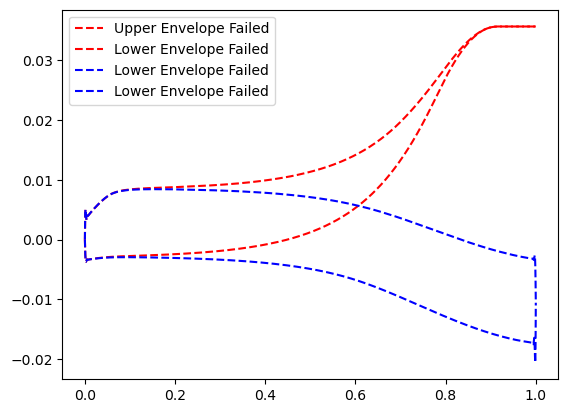

In [7]:
t_env_success, x_success_upper, x_success_lower = find_wavepacket_envelope(t_success, x_success, method='peaks')
t_env_fail, x_fail_upper, x_fail_lower = find_wavepacket_envelope(t_fail, x_fail, method='peaks')

plt.plot(t_env_fail, x_fail_upper, 'r--', label='Upper Envelope Failed')
plt.plot(t_env_fail, x_fail_lower, 'r--', label='Lower Envelope Failed')
plt.plot(t_env_success, x_success_upper, 'b--', label='Lower Envelope Failed')
plt.plot(t_env_success, x_success_lower, 'b--', label='Lower Envelope Failed')
plt.legend()
plt.savefig("oscillation_envolope_of_distance.pdf")
plt.show()

In [8]:
t_env_success, v_success_upper, v_success_lower = find_wavepacket_envelope(t_success, v_success, method='peaks')
t_env_fail, v_fail_upper, v_fail_lower = find_wavepacket_envelope(t_fail, v_fail, method='peaks')

plt.plot(t_env_fail, v_fail_upper, 'r--', label='Upper Envelope Failed')
plt.plot(t_env_fail, v_fail_lower, 'r--', label='Lower Envelope Failed')
plt.plot(t_env_success, v_success_upper, 'b--', label='Lower Envelope Failed')
plt.plot(t_env_success, v_success_lower, 'b--', label='Lower Envelope Failed')
plt.legend()
plt.savefig("oscillation_envolope_of_velocity.pdf")
plt.show()

/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_65194/4084609819.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("oscillation_envolope_of_velocity.pdf")
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_65194/4084609819.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("oscillation_envolope_of_velocity.pdf")
/Users/a1/miniforge3/envs/acoustic/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


KeyboardInterrupt: 

In [ ]:
plt.plot(t_env_fail, v_fail_upper, 'r--', label='Upper Envelope Failed')
plt.plot(t_env_fail, v_fail_lower, 'r--', label='Lower Envelope Failed')
plt.plot(t_env_success, v_success_upper, 'b--', label='Lower Envelope Failed')
plt.plot(t_env_success, v_success_lower, 'b--', label='Lower Envelope Failed')
plt.legend()

/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_13722/3191555571.py:6: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("oscillation_envolope.pdf")
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_13722/3191555571.py:6: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("oscillation_envolope.pdf")
/Users/a1/miniforge3/envs/acoustic/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


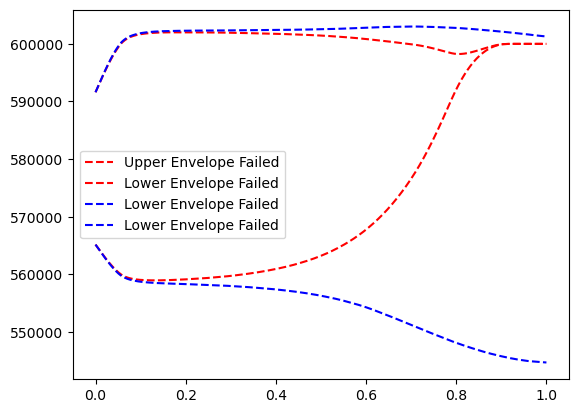

In [ ]:
plt.plot(t_success, P_fail_upper, 'r--', label='Upper Envelope Failed')
plt.plot(t_success, P_fail_lower, 'r--', label='Lower Envelope Failed')
plt.plot(t_success, P_success_upper, 'b--', label='Lower Envelope Failed')
plt.plot(t_success, P_success_lower, 'b--', label='Lower Envelope Failed')
plt.legend()
plt.savefig("oscillation_envolope.pdf")
plt.show()

In [9]:
n = 10000
t = t_success[::n]
P_fail_upper_s = P_fail_upper[::n]
P_fail_lower_s = P_fail_lower[::n]
P_fail_amplitude = P_fail_upper_s-P_fail_lower_s

x_fail_upper_s = x_fail_upper[::n]
x_fail_lower_s = x_fail_lower[::n]
x_fail_amplitude = x_fail_upper_s-x_fail_lower_s

P_success_upper_s = P_success_upper[::n]
P_success_lower_s = P_success_lower[::n]
P_success_amplitude = P_success_upper-P_success_lower

x_success_upper_s = x_success_upper[::n]
x_success_lower_s = x_success_lower[::n]
x_success_amplitude = x_success_upper_s-x_success_lower_s

v_success_upper_s = v_success_upper[::n]
v_success_lower_s = v_success_lower[::n]
v_success_amplitude = v_success_upper_s-v_success_lower_s

v_fail_upper_s = v_fail_upper[::n]
v_fail_lower_s = v_fail_lower[::n]
v_fail_amplitude = v_fail_upper_s-v_fail_lower_s


n_average=500000
t_death_s, P_death_average_s = np.mean(t_death.reshape(-1, n_average), axis=1), np.mean(P_death.reshape(-1, n_average), axis=1)

In [14]:
def reed_flow(dP, m_max, dP_max):
    """Mass flow rate through reed valve (positive for flow from high to low pressure)."""
    u = dP / dP_max
    if dP > 0 and dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return - m_max * (1 - u) * np.sqrt(np.abs(u))
    else:
        return 0.0


average_mass_flow_success = np.zeros_like(P_success_upper_s)
average_mass_flow_failure = np.zeros_like(P_success_upper_s)


average_enthalpy_flow_success = np.zeros_like(P_success_upper_s)
average_enthalpy_flow_failure = np.zeros_like(P_success_upper_s)


average_dissipation_flow_success = np.zeros_like(P_success_upper_s)
average_dissipation_flow_failure = np.zeros_like(P_success_upper_s)

def mass_flow(t): 
    P_cv =  A*np.sin(2*np.pi*t)+B
    dP_in = P_in - P_cv
    dP_out = P_cv - P_out

    m_in = reed_flow(dP_in,m_max,dP_max)
    m_out = reed_flow(dP_out,m_max,dP_max)
    return m_in-m_out

T_in = 300;
cp = 1050  # J/kg·K
cv = 744  # J/kg·K

def enthapy_flow(t):
    P_cv =  A*np.sin(2*np.pi*t)+B
    dP_in = P_in - P_cv
    dP_out = P_cv - P_out

    m_in = reed_flow(dP_in,m_max,dP_max)
    m_out = reed_flow(dP_out,m_max,dP_max)
    enthalpy_in = m_in * T_in * cp
    enthalpy_out = m_out*T_cv*cp
    return enthalpy_in - enthalpy_out

def dissipation(t):
    velocity = A*np.sin(2*np.pi*t)+B
    return b_gas*velocity**2

In [25]:
# resistance_success = np.zeros_like(P_success_upper_s)
# resistance_fail = np.zeros_like(P_success_upper_s)

# for i in range(len(resistance_success)):
#     dP_in = P_in - P_success_upper_s[i]
#     dP_out = P_success_upper_s[i] - P_out
#     m_in_high_P = reed_flow(dP_in,m_max,dP_max)
#     m_out_high_P = reed_flow(dP_out,m_max,dP_max)
#     m_high_P = m_in_high_P-m_out_high_P
#     dP_in = P_in - P_success_lower_s[i]
#     dP_out = P_success_lower_s[i] - P_out
#     m_in_low_P = reed_flow(dP_in,m_max,dP_max)
#     m_out_low_P = reed_flow(dP_out,m_max,dP_max)
#     m_low_P = m_in_low_P-m_out_low_P
#     resistance_success[i] = (m_high_P-m_low_P)/(P_fail_upper_s[i] - P_fail_lower_s[i])

# for i in range(len(resistance_success)):
#     dP_in = P_in - P_fail_upper_s[i]
#     dP_out = P_fail_upper_s[i] - P_out
#     m_in_high_P = reed_flow(dP_in,m_max,dP_max)
#     m_out_high_P = reed_flow(dP_out,m_max,dP_max)
#     m_high_P = m_in_high_P-m_out_high_P
#     dP_in = P_in - P_fail_lower_s[i]
#     dP_out = P_fail_lower_s[i] - P_out
#     m_in_low_P = reed_flow(dP_in,m_max,dP_max)
#     m_out_low_P = reed_flow(dP_out,m_max,dP_max)
#     m_low_P = m_in_low_P-m_out_low_P
#     resistance_fail[i] = (m_high_P-m_low_P)/(P_fail_upper_s[i] - P_fail_lower_s[i])

# plt.plot(t,resistance_success,label='success')
# plt.plot(t,resistance_fail,label='fail')
# plt.legend()
# plt.savefig("effectvie_resistance.png")

In [15]:

for i in range(len(average_mass_flow_success)):
    B = (P_success_upper_s[i] + P_success_lower_s[i])/2
    A = (P_success_upper_s[i] - P_success_lower_s[i])/2
    T_cv = T_success[i]
    val, err = quad(lambda tau: float(enthapy_flow(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
    average_enthalpy_flow_success[i] = val

for i in range(len(average_mass_flow_failure)):
    B = (P_fail_upper_s[i] + P_fail_lower_s[i])/2
    A = (P_fail_upper_s[i] - P_fail_lower_s[i])/2
    T_cv = T_fail[i]
    val, err = quad(lambda tau: float(enthapy_flow(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
    average_enthalpy_flow_failure[i] = val

/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_65194/3939202727.py:5: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  val, err = quad(lambda tau: float(enthapy_flow(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_65194/3939202727.py:12: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, di

In [ ]:
for i in range(len(average_mass_flow_success)):
    B = (P_success_upper_s[i] + P_success_lower_s[i])/2
    A = (P_success_upper_s[i] - P_success_lower_s[i])/2
    val, err = quad(lambda tau: float(mass_flow(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
    average_mass_flow_success[i] = val

for i in range(len(average_mass_flow_failure)):
    B = (P_fail_upper_s[i] + P_fail_lower_s[i])/2
    A = (P_fail_upper_s[i] - P_fail_lower_s[i])/2
    val, err = quad(lambda tau: float(mass_flow(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
    average_mass_flow_failure[i] = val

/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_39337/120551808.py:4: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  val, err = quad(lambda tau: float(mass_flow(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_39337/120551808.py:10: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discont

In [21]:
for i in range(len(average_mass_flow_success)):
    b_gas = b_gas_success
    B = (v_success_upper_s[i] + v_success_lower_s[i])/2
    A = (v_success_upper_s[i] - v_success_lower_s[i])/2
    val, err = quad(lambda tau: float(dissipation(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
    average_dissipation_flow_success[i] = val

for i in range(len(average_mass_flow_failure)):
    b_gas = b_gas_fail
    B = (v_fail_upper_s[i] + v_fail_lower_s[i])/2
    A = (v_fail_upper_s[i] - v_fail_lower_s[i])/2
    val, err = quad(lambda tau: float(dissipation(tau)), 0.0, 1.0, epsrel=1e-8, epsabs=1e-12)
    average_dissipation_flow_failure[i] = val

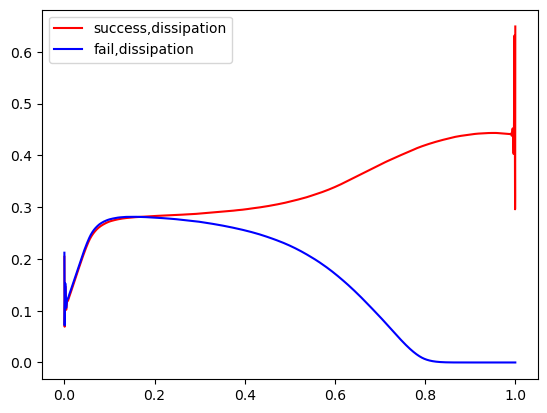

In [22]:
plt.plot(t, average_dissipation_flow_success,'r',label="success,dissipation")
plt.plot(t, average_dissipation_flow_failure,'b',label="fail,dissipation")
plt.legend()

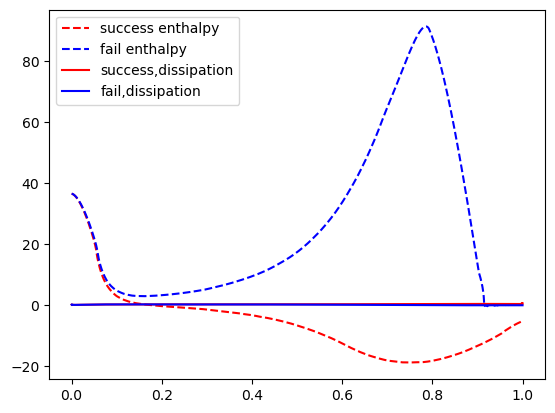

In [24]:
plt.plot(t, average_enthalpy_flow_success,'r--',label="success enthalpy")
plt.plot(t, average_enthalpy_flow_failure,'b--', label="fail enthalpy")
plt.plot(t, average_dissipation_flow_success,'r',label="success,dissipation")
plt.plot(t, average_dissipation_flow_failure,'b',label="fail,dissipation")
plt.legend()
plt.savefig("success_vs_failure_enthalpy_and_dissipation_flow.pdf")

In [20]:
b_gas_fail

array(0.00212058)

In [36]:
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

def peak_period_vs_time(t, x, prominence=None, distance=None, use_abs=False):
    """
    Find peaks in x(t), then return:
      - t_mid : midpoint time between each consecutive peak pair
      - T     : period length in seconds (t[next_peak] - t[this_peak])
      - peaks : indices of detected peaks (for debugging)

    Parameters
    ----------
    t : (N,) array-like  -- time (can be nonuniform, but must be increasing)
    x : (N,) array-like  -- signal
    prominence : float or None  -- passed to scipy.signal.find_peaks
    distance : int or None      -- min separation between peaks in *samples*
    use_abs : bool              -- detect peaks on |x| if the sign flips

    Returns
    -------
    t_mid : (K,) array
    T     : (K,) array  (seconds)
    peaks : (M,) array  (indices of peaks)
    """
    t = np.asarray(t)
    x = np.asarray(x)

    x_peaks = np.abs(x) if use_abs else x

    if prominence is None:
        rng = float(np.nanmax(x_peaks) - np.nanmin(x_peaks))
        prominence = 0.10 * rng if np.isfinite(rng) and rng > 0 else 0.0

    peaks, _ = find_peaks(x_peaks, prominence=prominence, distance=distance)
    if peaks.size < 2:
        return np.array([]), np.array([]), peaks

    # Actual period in seconds, using your time array
    T = t[peaks[1:]] - t[peaks[:-1]]
    t_mid = 0.5 * (t[peaks[1:]] + t[peaks[:-1]])
    return t_mid, T, peaks


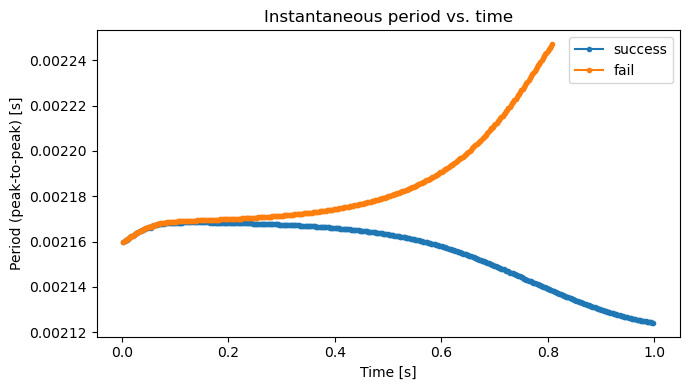

In [40]:


t_mid, T_success, peaks = peak_period_vs_time(t_success, P_success, prominence=None, distance=None)
t_mid_fail, T_fail, peaks_fail = peak_period_vs_time(t_fail, P_fail, prominence=None, distance=None)


plt.figure(figsize=(7,4))
plt.plot(t_mid, T_success, marker='o', ms=3,label='success')
plt.plot(t_mid_fail, T_fail, marker='o', ms=3,label='fail')

plt.xlabel("Time [s]")
plt.ylabel("Period (peak-to-peak) [s]")
plt.title("Instantaneous period vs. time")
plt.legend()
plt.tight_layout()
plt.savefig('fail_success_instantaneuous_period_v_time.pdf')
plt.show()

# (Optional) If you also want frequency vs. time:
# f = 1.0 / T


In [20]:
import numpy as np
from scipy.signal import find_peaks

def _dominant_period_samples(t, y, fs=None):
    """Estimate samples-per-period using FFT on a de-meaned, detrended signal."""
    t = np.asarray(t); y = np.asarray(y)
    if fs is None:
        dt = np.median(np.diff(t))
        fs = 1.0/dt
    # simple detrend
    coeffs = np.polyfit(t, y, 1)             # linear trend
    y_dt = y - (coeffs[0]*t + coeffs[1])     # detrended
    Y = np.fft.rfft(y_dt - np.mean(y_dt))
    freqs = np.fft.rfftfreq(y_dt.size, d=1.0/fs)
    if freqs.size <= 1:
        return max(1, int(round(fs* (t[-1]-t[0]) / 10)))  # fallback
    # ignore DC
    k = 1 + np.argmax(np.abs(Y[1:]))
    f_dom = freqs[k]
    if f_dom <= 0:
        return max(1, int(round(fs* (t[-1]-t[0]) / 10)))
    return max(1, int(round(fs / f_dom)))

def integrate_between_peaks_adaptive(
    t, m_dot, expected_freq=None, use_abs=False,
    min_cycles=3, verbose=True
):
    """
    Integrate mass flow between consecutive *maxima* with adaptive peak picking.
    Returns:
      t_cycle  : midpoint time of each cycle (peak-to-peak)
      m_cycle  : ∫ m_dot dt over each cycle (or ∫|m_dot| dt if use_abs)
      peaks    : indices of detected peaks
      info     : dict with chosen params for debugging
    """
    t = np.asarray(t); m = np.asarray(m_dot)
    if t.size < 3:
        return np.array([]), np.array([]), np.array([]), {}

    # sampling rate
    dt_med = np.median(np.diff(t))
    fs = 1.0/dt_med

    # estimate samples/period
    if expected_freq is not None and expected_freq > 0:
        period_samps = max(1, int(round(fs/expected_freq)))
    else:
        period_samps = _dominant_period_samples(t, m, fs=fs)

    # base signal for peak finding
    m_for_peaks = np.abs(m) if use_abs else m
    rng = float(np.nanmax(m_for_peaks) - np.nanmin(m_for_peaks))
    rng = rng if np.isfinite(rng) and rng > 0 else 1.0

    # Try a few progressively looser settings
    distance_factors   = [0.8, 0.6, 0.4, 0.25]
    prominence_factors = [0.15, 0.10, 0.05, 0.02]

    chosen = None
    peaks = np.array([], dtype=int)

    for df in distance_factors:
        distance = max(1, int(df*period_samps))
        for pf in prominence_factors:
            prominence = pf*rng
            peaks, _ = find_peaks(m_for_peaks, distance=distance, prominence=prominence)
            if peaks.size >= (min_cycles + 1):
                chosen = {"distance": distance, "prominence": prominence,
                          "period_samps": period_samps, "fs": fs}
                break
        if chosen is not None:
            break

    # If still too few peaks, last-resort: distance only
    if chosen is None:
        distance = max(1, int(0.25*period_samps))
        peaks, _ = find_peaks(m_for_peaks, distance=distance)
        chosen = {"distance": distance, "prominence": None,
                  "period_samps": period_samps, "fs": fs}
        if verbose:
            print("[warn] using distance-only peak picking; peaks:", peaks.size)

    if verbose:
        print(f"[peaks] count={peaks.size}, distance={chosen['distance']}, "
              f"prominence={chosen['prominence']}, period_samps≈{period_samps}, fs≈{fs:.3g} Hz")

    if peaks.size < 2:
        return np.array([]), np.array([]), peaks, chosen

    # integrate between peaks
    mm = np.abs(m) if use_abs else m
    t_cycle = []
    m_cycle = []
    for i0, i1 in zip(peaks[:-1], peaks[1:]):
        if i1 <= i0+1:
            continue
        m_cycle.append(np.trapz(mm[i0:i1+1], t[i0:i1+1]))
        t_cycle.append(0.5*(t[i0]+t[i1]))

    return np.array(t_cycle), np.array(m_cycle), peaks, chosen


In [11]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

def exponential_model(t, A, tau, C):
    """
    Exponential model: A * exp(-t/tau) + C
    
    Parameters:
    - A: amplitude
    - tau: time constant (decay constant)
    - C: offset
    """
    return A * np.exp(-t / tau) + C

def exponential_growth_model(t, A, tau, C):
    """
    Exponential growth model: A * (1 - exp(-t/tau)) + C
    """
    return A * (1 - np.exp(-t / tau)) + C

def tanh_model(t, A, tau, t0, C):
    """
    Tanh model: A * tanh((t - t0)/tau) + C
    
    Parameters:
    - A: amplitude
    - tau: time constant (controls steepness of transition)
    - t0: center time of transition
    - C: offset
    """
    return A * np.tanh((t - t0) / tau) + C

def double_tanh_model(t, A1, tau1, t1, A2, tau2, t2, C):
    """
    Double tanh model for rise and fall: 
    A1*tanh((t-t1)/tau1) + A2*tanh((t-t2)/tau2) + C
    
    Good for wavepackets that rise and then fall.
    """
    return A1 * np.tanh((t - t1) / tau1) + A2 * np.tanh((t - t2) / tau2) + C

def fit_exponential_decay(t, y, model='decay', initial_guess=None):
    """
    Fit exponential decay, growth, or tanh model to data and extract time constant.
    
    Parameters:
    -----------
    t : array-like
        Time array
    y : array-like
        Data array (e.g., envelope values)
    model : str
        'decay' for exponential decay
        'growth' for exponential growth
        'tanh' for hyperbolic tangent
        'double_tanh' for rise and fall
        'auto' to try all models and pick best fit
    initial_guess : tuple, optional
        Initial guess for parameters
        - decay/growth: (A, tau, C)
        - tanh: (A, tau, t0, C)
        - double_tanh: (A1, tau1, t1, A2, tau2, t2, C)
        
    Returns:
    --------
    params : dict
        Fitted parameters
    params_cov : array
        Covariance matrix of parameters
    fit_quality : dict
        R-squared and RMSE for fit quality
    """
    
    t = np.asarray(t)
    y = np.asarray(y)
    
    # Model selection and initial guess setup
    if model == 'auto':
        # Try all models and return the best
        best_result = None
        best_r2 = -np.inf
        best_model = None
        
        for m in ['decay', 'growth', 'tanh', 'double_tanh']:
            result = fit_exponential_decay(t, y, model=m)
            if result[0] is not None and result[2] is not None:
                if result[2]['r_squared'] > best_r2:
                    best_r2 = result[2]['r_squared']
                    best_result = result
                    best_model = m
        
        if best_result:
            print(f"Best model: {best_model} (R² = {best_r2:.4f})")
            return best_result
        else:
            return None, None, None
    
    # Set up model-specific parameters
    if model == 'decay':
        func = exponential_model
        if initial_guess is None:
            C_guess = np.mean([y[0], y[-1]])
            A_guess = y[0] - C_guess
            tau_guess = (t[-1] - t[0]) / 3
            initial_guess = (A_guess, tau_guess, C_guess)
            
    elif model == 'growth':
        func = exponential_growth_model
        if initial_guess is None:
            C_guess = y[0]
            A_guess = y[-1] - y[0]
            tau_guess = (t[-1] - t[0]) / 3
            initial_guess = (A_guess, tau_guess, C_guess)
            
    elif model == 'tanh':
        func = tanh_model
        if initial_guess is None:
            C_guess = (y[0] + y[-1]) / 2
            A_guess = (y[-1] - y[0]) / 2
            t0_guess = (t[0] + t[-1]) / 2
            tau_guess = (t[-1] - t[0]) / 6
            initial_guess = (A_guess, tau_guess, t0_guess, C_guess)
            
    elif model == 'double_tanh':
        func = double_tanh_model
        if initial_guess is None:
            # Find approximate peak location
            peak_idx = np.argmax(np.abs(y))
            t_peak = t[peak_idx]
            
            C_guess = (y[0] + y[-1]) / 2
            A1_guess = (y[peak_idx] - y[0])
            A2_guess = (y[-1] - y[peak_idx])
            t1_guess = (t[0] + t_peak) / 2
            t2_guess = (t_peak + t[-1]) / 2
            tau1_guess = (t_peak - t[0]) / 3
            tau2_guess = (t[-1] - t_peak) / 3
            initial_guess = (A1_guess, tau1_guess, t1_guess, A2_guess, tau2_guess, t2_guess, C_guess)
    else:
        raise ValueError("model must be 'decay', 'growth', 'tanh', 'double_tanh', or 'auto'")
    
    try:
        # Fit the model
        params, params_cov = curve_fit(func, t, y, p0=initial_guess, maxfev=10000)
        
        # Calculate fit quality
        y_fit = func(t, *params)
        residuals = y - y_fit
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r_squared = 1 - (ss_res / ss_tot)
        rmse = np.sqrt(np.mean(residuals**2))
        
        # Package results based on model
        if model in ['decay', 'growth']:
            param_dict = {
                'A': params[0],
                'tau': params[1],
                'C': params[2],
                'model': model
            }
        elif model == 'tanh':
            param_dict = {
                'A': params[0],
                'tau': params[1],
                't0': params[2],
                'C': params[3],
                'model': model
            }
        elif model == 'double_tanh':
            param_dict = {
                'A1': params[0],
                'tau1': params[1],
                't1': params[2],
                'A2': params[3],
                'tau2': params[4],
                't2': params[5],
                'C': params[6],
                'model': model
            }
        
        fit_quality = {
            'r_squared': r_squared,
            'rmse': rmse
        }
        
        return param_dict, params_cov, fit_quality
        
    except RuntimeError as e:
        print(f"Fitting failed for {model}: {e}")
        return None, None, None

def analyze_envelope_decay(t, upper_env, lower_env, model='auto'):
    """
    Analyze both upper and lower envelopes for decay constants.
    
    Parameters:
    -----------
    t : array-like
        Time array
    upper_env : array-like
        Upper envelope
    lower_env : array-like
        Lower envelope
    model : str
        Model to fit: 'decay', 'growth', 'tanh', 'double_tanh', or 'auto'
        
    Returns:
    --------
    results : dict
        Dictionary containing fit results for both envelopes
    """
    
    results = {}
    
    # Fit upper envelope
    print("Fitting upper envelope...")
    params_upper, cov_upper, quality_upper = fit_exponential_decay(
        t, upper_env, model=model
    )
    
    if params_upper:
        results['upper'] = {
            'params': params_upper,
            'covariance': cov_upper,
            'quality': quality_upper
        }
        model_type = params_upper.get('model', model)
        if 'tau' in params_upper:
            print(f"Upper envelope ({model_type}) - tau: {params_upper['tau']:.6f} s, R²: {quality_upper['r_squared']:.4f}")
        elif 'tau1' in params_upper:
            print(f"Upper envelope ({model_type}) - tau1: {params_upper['tau1']:.6f} s, tau2: {params_upper['tau2']:.6f} s, R²: {quality_upper['r_squared']:.4f}")
    
    # Fit lower envelope
    print("\nFitting lower envelope...")
    params_lower, cov_lower, quality_lower = fit_exponential_decay(
        t, lower_env, model=model
    )
    
    if params_lower:
        results['lower'] = {
            'params': params_lower,
            'covariance': cov_lower,
            'quality': quality_lower
        }
        model_type = params_lower.get('model', model)
        if 'tau' in params_lower:
            print(f"Lower envelope ({model_type}) - tau: {params_lower['tau']:.6f} s, R²: {quality_lower['r_squared']:.4f}")
        elif 'tau1' in params_lower:
            print(f"Lower envelope ({model_type}) - tau1: {params_lower['tau1']:.6f} s, tau2: {params_lower['tau2']:.6f} s, R²: {quality_lower['r_squared']:.4f}")
    
    return results

def plot_decay_fits(t, upper_env, lower_env, results):
    """
    Plot the envelopes with fitted curves.
    """
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
    
    t_fit = np.linspace(t[0], t[-1], 200)
    
    # Upper envelope
    if 'upper' in results:
        params = results['upper']['params']
        model = params.get('model', 'decay')
        
        # Generate fit curve based on model
        if model == 'decay':
            y_fit = exponential_model(t_fit, params['A'], params['tau'], params['C'])
        elif model == 'growth':
            y_fit = exponential_growth_model(t_fit, params['A'], params['tau'], params['C'])
        elif model == 'tanh':
            y_fit = tanh_model(t_fit, params['A'], params['tau'], params['t0'], params['C'])
        elif model == 'double_tanh':
            y_fit = double_tanh_model(t_fit, params['A1'], params['tau1'], params['t1'],
                                      params['A2'], params['tau2'], params['t2'], params['C'])
        
        ax1.plot(t, upper_env, 'b.', alpha=0.5, label='Data')
        ax1.plot(t_fit, y_fit, 'r-', linewidth=2, 
                label=f"Fit ({model}): R²={results['upper']['quality']['r_squared']:.4f}")
        ax1.set_xlabel('Time (s)')
        ax1.set_ylabel('Upper Envelope')
        ax1.set_title('Upper Envelope Fit')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Add tau info to legend
        if 'tau' in params:
            ax1.text(0.02, 0.98, f"τ = {params['tau']:.4f} s", 
                    transform=ax1.transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        elif 'tau1' in params:
            ax1.text(0.02, 0.98, f"τ₁ = {params['tau1']:.4f} s\nτ₂ = {params['tau2']:.4f} s", 
                    transform=ax1.transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # Lower envelope
    if 'lower' in results:
        params = results['lower']['params']
        model = params.get('model', 'decay')
        
        # Generate fit curve based on model
        if model == 'decay':
            y_fit = exponential_model(t_fit, params['A'], params['tau'], params['C'])
        elif model == 'growth':
            y_fit = exponential_growth_model(t_fit, params['A'], params['tau'], params['C'])
        elif model == 'tanh':
            y_fit = tanh_model(t_fit, params['A'], params['tau'], params['t0'], params['C'])
        elif model == 'double_tanh':
            y_fit = double_tanh_model(t_fit, params['A1'], params['tau1'], params['t1'],
                                      params['A2'], params['tau2'], params['t2'], params['C'])
        
        ax2.plot(t, lower_env, 'b.', alpha=0.5, label='Data')
        ax2.plot(t_fit, y_fit, 'r-', linewidth=2,
                label=f"Fit ({model}): R²={results['lower']['quality']['r_squared']:.4f}")
        ax2.set_xlabel('Time (s)')
        ax2.set_ylabel('Lower Envelope')
        ax2.set_title('Lower Envelope Fit')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        # Add tau info
        if 'tau' in params:
            ax2.text(0.02, 0.98, f"τ = {params['tau']:.4f} s", 
                    transform=ax2.transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        elif 'tau1' in params:
            ax2.text(0.02, 0.98, f"τ₁ = {params['tau1']:.4f} s\nτ₂ = {params['tau2']:.4f} s", 
                    transform=ax2.transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.show()

# Example usage


Fitting upper envelope...
Upper envelope (tanh) - tau: 0.106752 s, R²: 0.9982

Fitting lower envelope...
Lower envelope (tanh) - tau: 0.165833 s, R²: nan


/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_39337/3992241120.py:145: OptimizeWarning: Covariance of the parameters could not be estimated
  params, params_cov = curve_fit(func, t, y, p0=initial_guess, maxfev=10000)
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_39337/3992241120.py:152: RuntimeWarning: invalid value encountered in scalar divide
  r_squared = 1 - (ss_res / ss_tot)


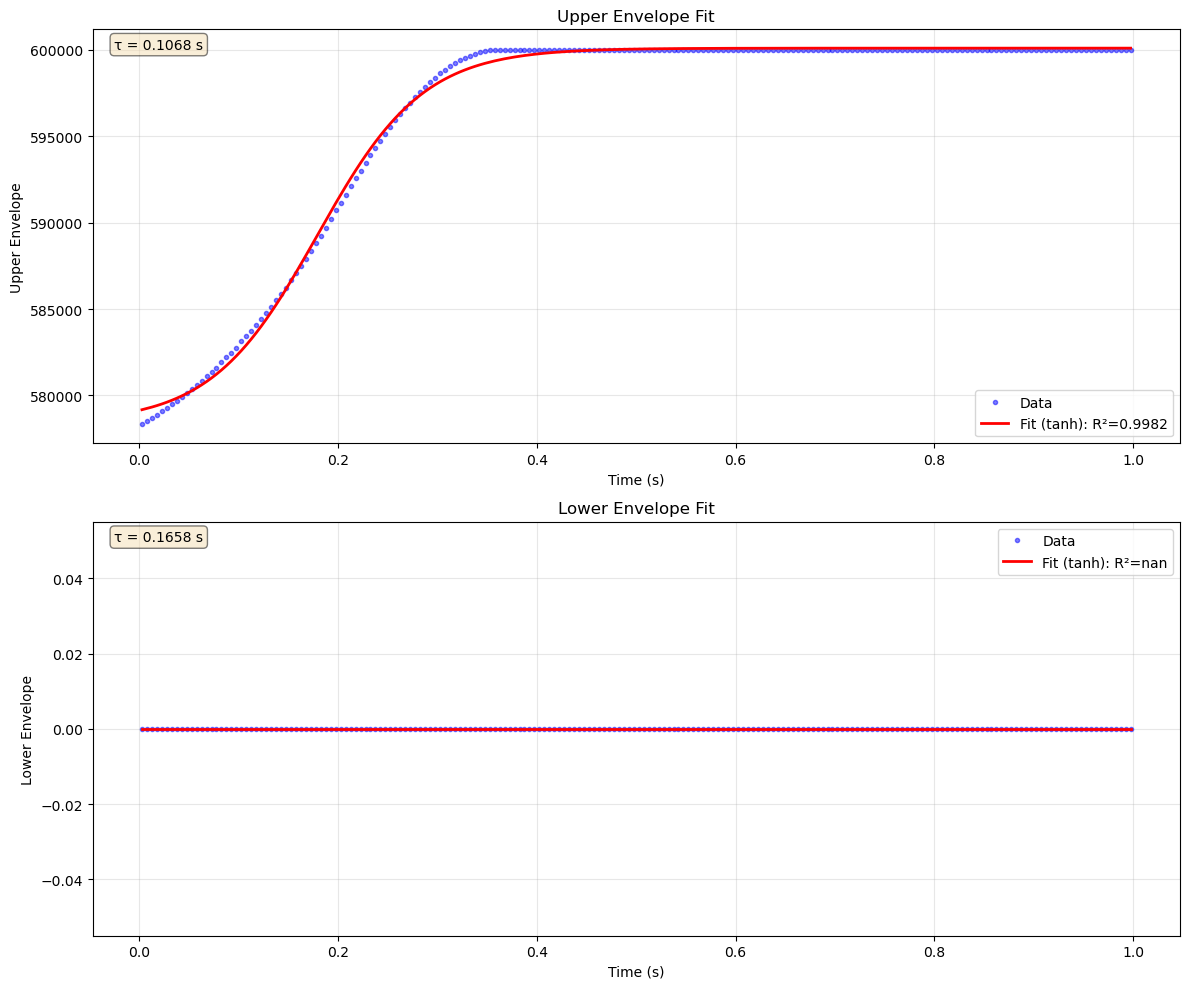

In [70]:
if __name__ == "__main__":
    # Generate example data with tanh-like behavior    
    # Example 1: Double tanh (rise and fall) - like your wavepacket
    # Analyze with auto model selection
    # print("=== Using AUTO model selection ===")
    # results_auto = analyze_envelope_decay(t, P_fail_upper_s, P_fail_lower_s, model='auto')
    # plot_decay_fits(t, P_fail_upper_s, P_fail_lower_s, results_auto)
    
    # Or force specific model
    # print("\n=== Using DOUBLE_TANH model ===")
    results = analyze_envelope_decay(t_death_s, P_death_average_s, np.zeros_like(P_death_average_s), model='tanh')
    plot_decay_fits(t_death_s, P_death_average_s, np.zeros_like(P_death_average_s), results)

In [29]:
arr = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

# Define the number of first elements to retrieve
n = 5

# Get the first n elements
first_n_elements = arr[:n]

# Print the result
print(first_n_elements)

[10 20 30 40 50]


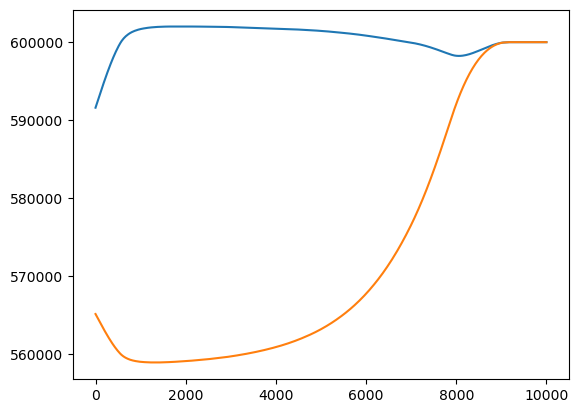

In [47]:
plt.plot(P_fail_upper_s[:20000])
plt.plot(P_fail_lower_s[:20000])

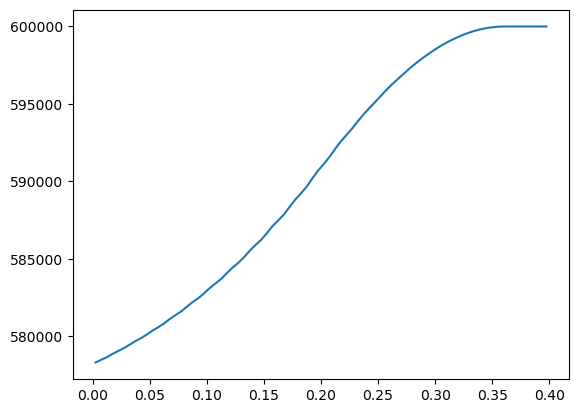

In [68]:
plt.plot(t_death_s[:80],P_death_average_s[:80])

In [3]:
y_0=1
beta = 0.1
omega_0 = 100
## m = 1, xi = 1, A_D = 1
def x_0(omega):
    x_0 = y_0/((omega_0**2-omega**2)+ 1j*beta*omega)
    return np.real(x_0), np.imag(x_0)

mdot_0 = 1 
def x_0_and_mdot(omega):
    x_0 = -1j*mdot_0/(1j*omega**2-omega**3+omega*omega_0**2)
    return np.real(x_0), np.imag(x_0)

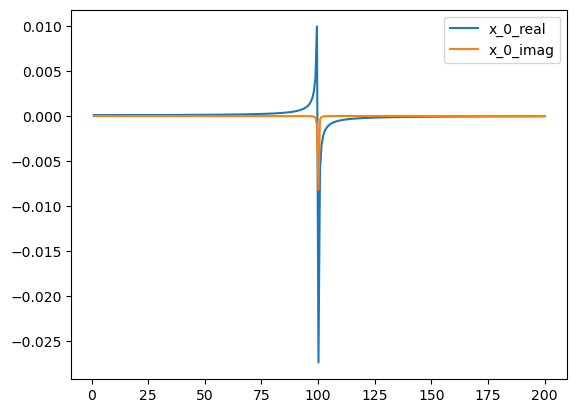

In [4]:
omega_array = np.linspace(1,200,300)
x_0_real = np.zeros_like(omega_array)
x_0_imag = np.zeros_like(omega_array)

for i in range(len(omega_array)):
    x_0_real[i],x_0_imag[i] = x_0(omega_array[i])
    
plt.plot(omega_array,x_0_real,label='x_0_real')
plt.plot(omega_array,x_0_imag,label='x_0_imag')
plt.legend()
plt.show()

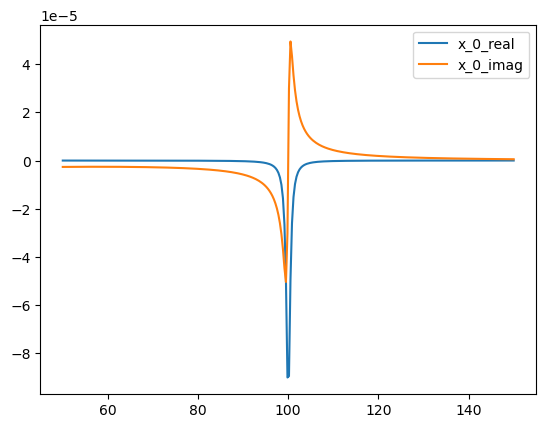

In [5]:
omega_array = np.linspace(50,150,300)
x_0_real = np.zeros_like(omega_array)
x_0_imag = np.zeros_like(omega_array)

for i in range(len(omega_array)):
    x_0_real[i],x_0_imag[i] = x_0_and_mdot(omega_array[i])
    
plt.plot(omega_array,x_0_real,label='x_0_real')
plt.plot(omega_array,x_0_imag,label='x_0_imag')
plt.legend()
plt.show()

In [6]:
L=1e-4
gamma = 1.4

In [7]:
def P_from_x(omega,t):
    x_0, _ = x_0_and_mdot(omega)
    x = x_0*np.cos(t*omega)
    P = (L+3*x)**(-gamma)
    return P

t = np.linspace(0,5,2000)
P1 = np.zeros_like(t)
P2 = np.zeros_like(t)

for i in range(len(t)):
    P1[i] = P_from_x(98,t[i])
    P2[i]= P_from_x(110,t[i])

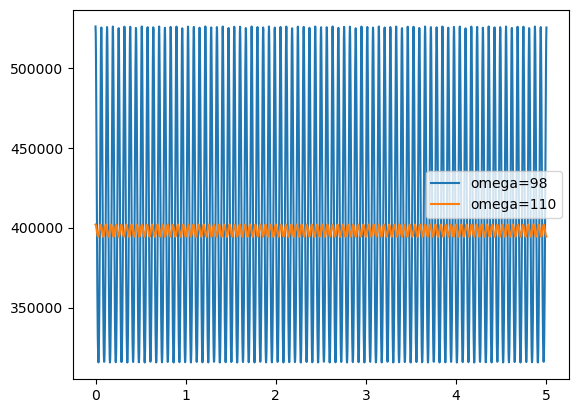

In [8]:
plt.plot(t,P1,label="omega=98")
plt.plot(t,P2,label="omega=110")
plt.legend()
plt.show()


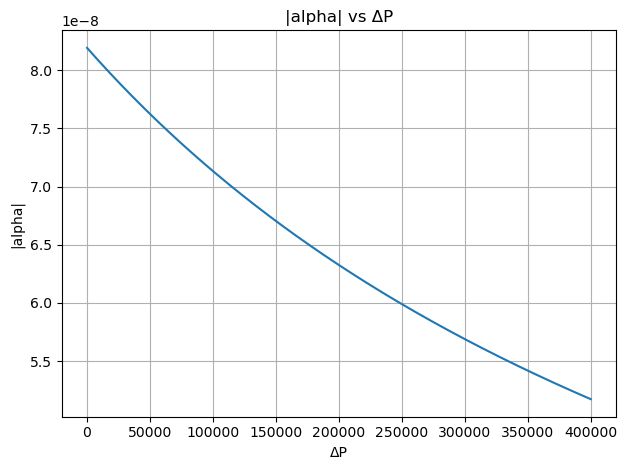

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def alpha_of_dP(dP, *, P0, AR, L, AD, rho, omega, beta, m, omega0, xi, gamma):
    """
    Compute alpha(ΔP) from the expression in the screenshot.

    Parameters
    ----------
    dP : array-like
        ΔP values (Pa). Avoid ΔP=0 because expression has 1/ΔP.
    Other parameters : floats
        P0, AR, L, AD, rho, omega, beta, m, omega0, xi, gamma

    Returns
    -------
    alpha : complex ndarray
    """
    dP = np.asarray(dP, dtype=float)

    # Avoid division by zero
    if np.any(dP == 0):
        raise ValueError("ΔP includes 0; alpha has a 1/ΔP singularity. Remove ΔP=0 from the grid.")

    X = (AR * L) ** (-gamma) * (P0 + dP) / P0
    complex_factor = beta * omega + 1j * m * (omega - omega0) * (omega + omega0)

    alpha = (AD * (X ** (-1.0 / gamma)) *
             (-1.0 + (AR * L) * (X ** (1.0 / gamma))) *
             rho * omega * complex_factor) / (3.0 * AR * dP * xi)

    return alpha


def plot_alpha_vs_dP(dP_min, dP_max, npts=2000, *, mode="real", **params):
    """
    Plot alpha(ΔP) across a ΔP range.

    mode: 'real', 'imag', 'abs', or 'phase'
    params: passed to alpha_of_dP (P0, AR, L, AD, rho, omega, beta, m, omega0, xi, gamma)
    """
    dP = np.linspace(dP_min, dP_max, npts)

    # remove/skip 0 if it lies in the interval
    dP = dP[dP != 0.0]

    a = alpha_of_dP(dP, **params)

    if mode == "real":
        y = np.real(a); ylabel = "Re(alpha)"
    elif mode == "imag":
        y = np.imag(a); ylabel = "Im(alpha)"
    elif mode == "abs":
        y = np.abs(a); ylabel = "|alpha|"
    elif mode == "phase":
        y = np.angle(a); ylabel = "arg(alpha) [rad]"
    else:
        raise ValueError("mode must be one of: 'real', 'imag', 'abs', 'phase'")

    plt.figure()
    plt.plot(dP, y)
    plt.xlabel("ΔP")
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} vs ΔP")
    plt.grid(True)
    plt.tight_layout()
    plt.show()



AR=0.02 #m^2
AD = 0.002 #m^2
L=1 #m
rho = 4 #kg/m^3
m = 1.0/3.0*rho*AR*L
P0 = 572500.0
gamma = 1.4
xi = P0*gamma*AD*AR/(AR*L)
omega = 2*np.pi*100
beta = 0.1
plot_alpha_vs_dP(
    dP_min=0, dP_max=4e5, npts=2000, mode="abs",
    P0=P0, AR=AR, L=L, AD=AD, rho=rho,
    omega=omega, beta=beta, m=m, omega0=omega,
    xi=xi, gamma=gamma
)


In [3]:
def non_dimensional_alpha(delta_P, omega,constant=1,m=0.001):
    return constant* 1.0/delta_P*(1+delta_P)**(-1.0/gamma)*(-1+(1+delta_P)**(gamma))*omega*(omega+1j*m*(omega-1)*(omega+1))

/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_55219/2963241480.py:2: RuntimeWarning: divide by zero encountered in scalar divide
  return constant* 1.0/delta_P*(1+delta_P)**(-1.0/gamma)*(-1+(1+delta_P)**(gamma))*omega*(omega+1j*m*(omega-1)*(omega+1))
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_55219/2963241480.py:2: RuntimeWarning: invalid value encountered in scalar multiply
  return constant* 1.0/delta_P*(1+delta_P)**(-1.0/gamma)*(-1+(1+delta_P)**(gamma))*omega*(omega+1j*m*(omega-1)*(omega+1))
/var/folders/tn/t7f1zc4n47g4wsjd6njxbp0r0000gn/T/ipykernel_55219/305358969.py:6: ComplexWarning: Casting complex values to real discards the imaginary part
  alpha[i] = non_dimensional_alpha(dP[i],omega)


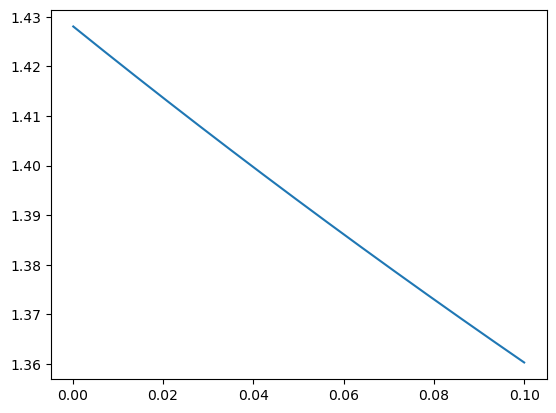

In [6]:
gamma=1.4
dP = np.linspace(0.0, 0.1, 1000)
alpha = np.zeros_like(dP)
omega = 1.01
for i in range(len(dP)):
    alpha[i] = non_dimensional_alpha(dP[i],omega)
    
plt.plot(dP,alpha)